In [28]:
#import libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans

from sklearn.decomposition import PCA

from sklearn.metrics import silhouette_score

import joblib

In [29]:
#load dataset
pd.read_csv(r"D:\vs\final project1\EHR\patients.csv")

,patient_id,age,sex,bmi,systolic_bp,diastolic_bp,heart_rate,temperature_f,smoking_status,alcohol_use,...,dx_heart_failure,dx_atrial_fibrillation,dx_chronic_kidney_disease,dx_copd,dx_asthma,dx_depression,dx_anxiety,dx_hypothyroidism,dx_osteoarthritis,dx_type1_diabetes
0,P0000001,66,M,23.5,148,81,64,98.4,former,light,...,0,0,1,0,0,0,0,0,1,0
1,P0000002,75,M,24.8,158,86,45,99.5,never,moderate,...,0,0,0,0,1,0,0,0,1,0
2,P0000003,82,M,17.8,135,57,90,98.2,never,light,...,0,0,1,0,0,0,0,0,0,0
3,P0000004,73,F,28.1,118,83,102,98.9,former,moderate,...,0,0,0,0,0,0,0,0,0,0
4,P0000005,86,F,30.6,156,81,56,98.7,never,heavy,...,0,0,0,0,1,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,P0099996,37,M,24.9,106,101,93,98.9,never,light,...,0,0,0,0,0,0,0,0,0,0
99996,P0099997,37,F,27.8,80,95,63,98.7,never,moderate,...,0,0,0,0,0,0,0,1,0,0
99997,P0099998,50,F,28.5,115,83,53,99.2,never,moderate,...,0,0,0,0,0,0,0,0,0,0
99998,P0099999,85,M,34.6,149,73,65,98.5,never,none,...,0,0,0,1,1,0,0,0,1,0


In [30]:
df = pd.read_csv(r"D:\vs\final project1\EHR\patients.csv")

In [31]:
df.head

<bound method NDFrame.head of       patient_id  age sex   bmi  systolic_bp  diastolic_bp  heart_rate  \
0       P0000001   66   M  23.5          148            81          64   
1       P0000002   75   M  24.8          158            86          45   
2       P0000003   82   M  17.8          135            57          90   
3       P0000004   73   F  28.1          118            83         102   
4       P0000005   86   F  30.6          156            81          56   
...          ...  ...  ..   ...          ...           ...         ...   
99995   P0099996   37   M  24.9          106           101          93   
99996   P0099997   37   F  27.8           80            95          63   
99997   P0099998   50   F  28.5          115            83          53   
99998   P0099999   85   M  34.6          149            73          65   
99999   P0100000   87   F  36.1          134            77          93   

       temperature_f smoking_status alcohol_use  ... dx_heart_failure  \
0       

In [32]:
df.shape

(100000, 28)

In [33]:
df.columns

Index(['patient_id', 'age', 'sex', 'bmi', 'systolic_bp', 'diastolic_bp',
       'heart_rate', 'temperature_f', 'smoking_status', 'alcohol_use',
       'exercise_level', 'insurance_type', 'charlson_index', 'dx_hypertension',
       'dx_type2_diabetes', 'dx_hyperlipidemia', 'dx_obesity',
       'dx_coronary_artery_disease', 'dx_heart_failure',
       'dx_atrial_fibrillation', 'dx_chronic_kidney_disease', 'dx_copd',
       'dx_asthma', 'dx_depression', 'dx_anxiety', 'dx_hypothyroidism',
       'dx_osteoarthritis', 'dx_type1_diabetes'],
      dtype='object')

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   patient_id                  100000 non-null  object 
 1   age                         100000 non-null  int64  
 2   sex                         100000 non-null  object 
 3   bmi                         100000 non-null  float64
 4   systolic_bp                 100000 non-null  int64  
 5   diastolic_bp                100000 non-null  int64  
 6   heart_rate                  100000 non-null  int64  
 7   temperature_f               100000 non-null  float64
 8   smoking_status              100000 non-null  object 
 9   alcohol_use                 100000 non-null  object 
 10  exercise_level              100000 non-null  object 
 11  insurance_type              100000 non-null  object 
 12  charlson_index              100000 non-null  int64  
 13  dx_hypertension

In [35]:
#Check Missing Values
df.isnull().sum()

patient_id                    0
age                           0
sex                           0
bmi                           0
systolic_bp                   0
diastolic_bp                  0
heart_rate                    0
temperature_f                 0
smoking_status                0
alcohol_use                   0
exercise_level                0
insurance_type                0
charlson_index                0
dx_hypertension               0
dx_type2_diabetes             0
dx_hyperlipidemia             0
dx_obesity                    0
dx_coronary_artery_disease    0
dx_heart_failure              0
dx_atrial_fibrillation        0
dx_chronic_kidney_disease     0
dx_copd                       0
dx_asthma                     0
dx_depression                 0
dx_anxiety                    0
dx_hypothyroidism             0
dx_osteoarthritis             0
dx_type1_diabetes             0
dtype: int64

In [36]:
#Remove identifiers columns
df = df.drop(
    ['patient_id'],
    axis=1
)

In [41]:
#Remove noisy sparse feature
df = df.drop(
    ['dx_type1_diabetes'],
    axis=1
)

In [42]:
#Define Features
#Clinically meaningful features
features = [

    # demographics
    'age',
    'sex',
    'bmi',

    # vitals
    'systolic_bp',
    'diastolic_bp',
    'heart_rate',
    'temperature_f',

    # behavioral
    'smoking_status',
    'alcohol_use',
    'exercise_level',

    # insurance
    'insurance_type',

    # disease burden
    'charlson_index',

    # diagnoses
    'dx_hypertension',
    'dx_type2_diabetes',
    'dx_hyperlipidemia',
    'dx_obesity',
    'dx_coronary_artery_disease',
    'dx_heart_failure',
    'dx_atrial_fibrillation',
    'dx_chronic_kidney_disease',
    'dx_copd',
    'dx_asthma',
    'dx_depression',
    'dx_anxiety',
    'dx_hypothyroidism',
    'dx_osteoarthritis'
]

In [45]:
#create clustering dataframe
X = df[features]

In [46]:
X.shape

(100000, 26)

In [47]:
df.columns.tolist()

['age',
 'sex',
 'bmi',
 'systolic_bp',
 'diastolic_bp',
 'heart_rate',
 'temperature_f',
 'smoking_status',
 'alcohol_use',
 'exercise_level',
 'insurance_type',
 'charlson_index',
 'dx_hypertension',
 'dx_type2_diabetes',
 'dx_hyperlipidemia',
 'dx_obesity',
 'dx_coronary_artery_disease',
 'dx_heart_failure',
 'dx_atrial_fibrillation',
 'dx_chronic_kidney_disease',
 'dx_copd',
 'dx_asthma',
 'dx_depression',
 'dx_anxiety',
 'dx_hypothyroidism',
 'dx_osteoarthritis']

In [48]:
X.head()

,age,sex,bmi,systolic_bp,diastolic_bp,heart_rate,temperature_f,smoking_status,alcohol_use,exercise_level,...,dx_coronary_artery_disease,dx_heart_failure,dx_atrial_fibrillation,dx_chronic_kidney_disease,dx_copd,dx_asthma,dx_depression,dx_anxiety,dx_hypothyroidism,dx_osteoarthritis
0,66,M,23.5,148,81,64,98.4,former,light,moderate,...,0,0,0,1,0,0,0,0,0,1
1,75,M,24.8,158,86,45,99.5,never,moderate,moderate,...,0,0,0,0,0,1,0,0,0,1
2,82,M,17.8,135,57,90,98.2,never,light,moderate,...,1,0,0,1,0,0,0,0,0,0
3,73,F,28.1,118,83,102,98.9,former,moderate,moderate,...,0,0,0,0,0,0,0,0,0,0
4,86,F,30.6,156,81,56,98.7,never,heavy,sedentary,...,0,0,0,0,0,1,1,0,1,0


In [49]:
#Encode categorical variables
X = pd.get_dummies(
    X,
    drop_first=True
)

print(X.shape)

(100000, 34)


In [50]:
print(X.dtypes)

age                             int64
bmi                           float64
systolic_bp                     int64
diastolic_bp                    int64
heart_rate                      int64
temperature_f                 float64
charlson_index                  int64
dx_hypertension                 int64
dx_type2_diabetes               int64
dx_hyperlipidemia               int64
dx_obesity                      int64
dx_coronary_artery_disease      int64
dx_heart_failure                int64
dx_atrial_fibrillation          int64
dx_chronic_kidney_disease       int64
dx_copd                         int64
dx_asthma                       int64
dx_depression                   int64
dx_anxiety                      int64
dx_hypothyroidism               int64
dx_osteoarthritis               int64
sex_M                            bool
smoking_status_former            bool
smoking_status_never             bool
alcohol_use_light                bool
alcohol_use_moderate             bool
alcohol_use_

In [51]:
#Feature Scaling(KMeans)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)

(100000, 34)


In [58]:
#After Scaling
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []

silhouette_scores = []

K = range(2, 11)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(
        X_scaled
    )

    inertia.append(
        kmeans.inertia_
    )

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_scores.append(score)

    print(
        "Clusters:",
        k,
        "Silhouette Score:",
        round(score, 3)
    )

Clusters: 2 Silhouette Score: 0.085
Clusters: 3 Silhouette Score: 0.047
Clusters: 4 Silhouette Score: 0.056
Clusters: 5 Silhouette Score: 0.056
Clusters: 6 Silhouette Score: 0.052
Clusters: 7 Silhouette Score: 0.046
Clusters: 8 Silhouette Score: 0.041
Clusters: 9 Silhouette Score: 0.049
Clusters: 10 Silhouette Score: 0.048


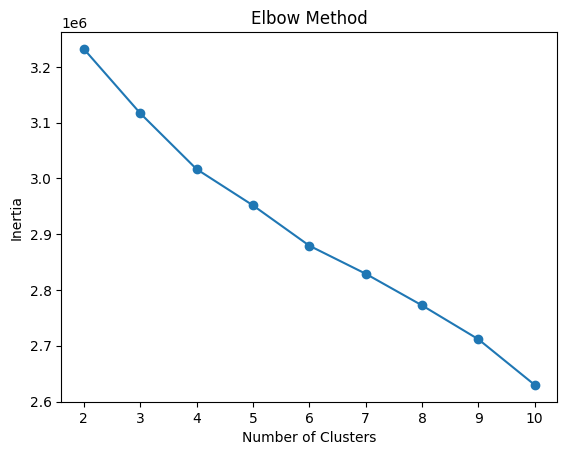

In [55]:
#Plot elbow curve
import matplotlib.pyplot as plt

plt.plot(
    K,
    inertia,
    marker='o'
)

plt.xlabel("Number of Clusters")

plt.ylabel("Inertia")

plt.title("Elbow Method")

plt.show()

In [59]:
#Final model
FINAL_K = 4

kmeans = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(
    X_scaled
)

In [60]:
#Assign Clusters
df['Cluster'] = clusters

print(
    df['Cluster'].value_counts()
)

Cluster
0    31305
2    29062
1    21540
3    18093
Name: count, dtype: int64


In [61]:
#PCA visualization
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(
    X_scaled
)

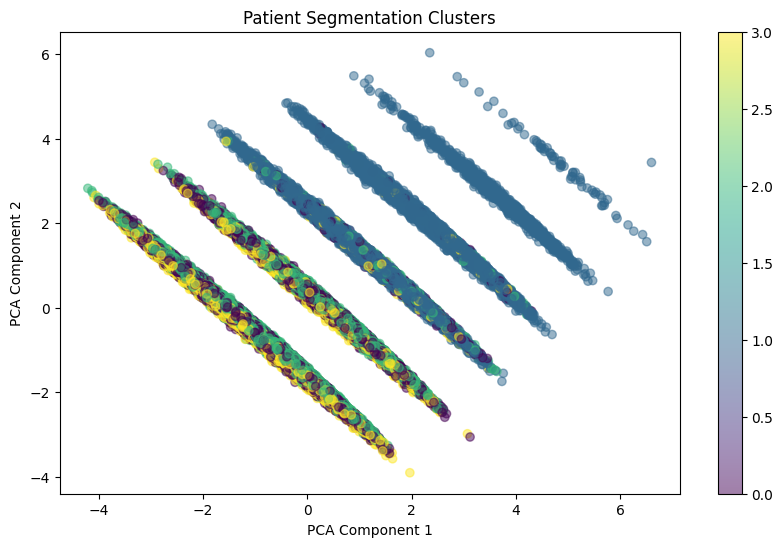

In [62]:
#Visualize clusters
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

scatter = plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=clusters,
    alpha=0.5
)

plt.xlabel("PCA Component 1")

plt.ylabel("PCA Component 2")

plt.title(
    "Patient Segmentation Clusters"
)

plt.colorbar(scatter)

plt.show()

In [63]:
#Cluster profiling
cluster_profile = df.groupby(
    'Cluster'
).mean(
    numeric_only=True
)

print(cluster_profile)

               age        bmi  systolic_bp  diastolic_bp  heart_rate  \
Cluster                                                                
0        70.387670  27.488900   133.196901     84.104712   71.996965   
1        75.835794  27.489304   135.274188     85.219359   72.011653   
2        70.544422  27.551428   133.165474     84.164648   72.101335   
3        70.540098  27.525297   133.272868     84.267396   71.957940   

         temperature_f  charlson_index  dx_hypertension  dx_type2_diabetes  \
Cluster                                                                      
0            98.600089        0.379428         0.664494           0.156205   
1            98.602228        2.404968         0.712581           0.167224   
2            98.604384        0.378398         0.667470           0.155082   
3            98.609810        0.374178         0.670757           0.152048   

         dx_hyperlipidemia  ...  dx_coronary_artery_disease  dx_heart_failure  \
Cluster          

In [64]:
#Interpretation Layer(Human)
cluster_names = {
    0: "General Moderate-Risk",
    1: "High Chronic Disease Burden",
    2: "Stable Low-Comorbidity",
    3: "Mild Cardiometabolic Risk"
}

df['Cluster_Label'] = df['Cluster'].map(
    cluster_names
)

In [65]:
#Save models
import joblib

joblib.dump(
    kmeans,
    "kmeans_model.pkl"
)

['kmeans_model.pkl']

In [66]:
#save Scaler
joblib.dump(
    scaler,
    "scaler.pkl"
)

['scaler.pkl']

In [67]:
#save feature columns
joblib.dump(
    X.columns.tolist(),
    "cluster_columns.pkl"
)

['cluster_columns.pkl']

In [68]:
#prediction function
def predict_cluster(new_patient):

    scaled_data = scaler.transform(
        new_patient
    )

    cluster = kmeans.predict(
        scaled_data
    )[0]

    cluster_name = cluster_names[
        cluster
    ]

    return cluster, cluster_name

In [69]:
#sample inference test
sample_patient = X.iloc[[0]]

cluster_id, cluster_label = predict_cluster(
    sample_patient
)

print("Cluster ID:", cluster_id)

print("Cluster Label:", cluster_label)

Cluster ID: 1
Cluster Label: High Chronic Disease Burden
